# Themes: fitting into the host

Charts should look native wherever they are shown. pyChartist offers: built-in light/dark themes; `theme='inherit'` to adopt the host's active matplotlib/seaborn style or Plotly template; presets for Jupyter, VS Code, Colab, GitHub and every Bootstrap (Dash) theme; `*-transparent` variants; and builders for your own brand.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
import pandas as pd
import pychartist as pc
import plotly.io as pio
pio.renderers.default = "plotly_mimetype+notebook_connected"   # renders in JupyterLab/VS Code/Colab; plotly.js from CDN

In [2]:
pen = pc.datasets.load('penguins')
sorted(pc.available_themes())[:20]

['bootstrap',
 'bootstrap-transparent',
 'cerulean',
 'cerulean-transparent',
 'chartist',
 'chartist-transparent',
 'colab-dark',
 'colab-dark-transparent',
 'colab-light',
 'colab-light-transparent',
 'cosmo',
 'cosmo-transparent',
 'cyborg',
 'cyborg-transparent',
 'd3',
 'd3-transparent',
 'dark',
 'dark-transparent',
 'darkly',
 'darkly-transparent']

## Light and dark

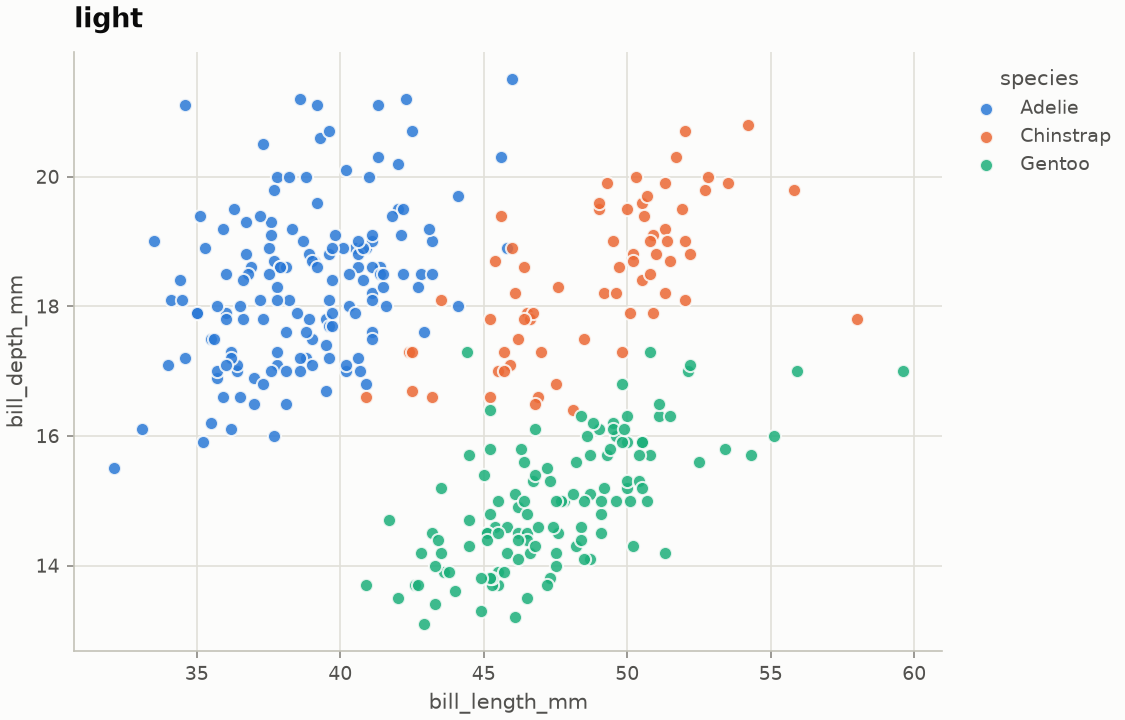

In [3]:
pc.scatter(pen, 'bill_length_mm', 'bill_depth_mm', 'species', theme='light', title='light')

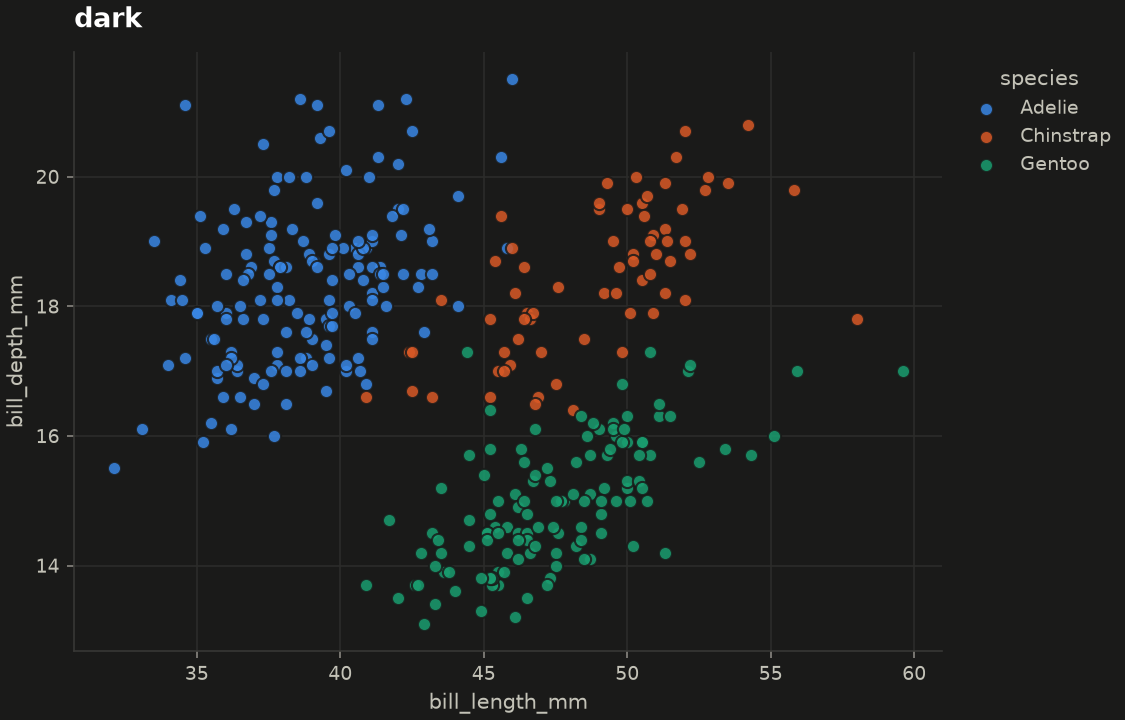

In [4]:
pc.scatter(pen, 'bill_length_mm', 'bill_depth_mm', 'species', theme='dark', title='dark')

In [5]:
pc.violin(pen, 'species', 'body_mass_g', theme='dark', backend='plotly', title='dark (plotly)')

<Chart kind='violin' backend='plotly' theme='pychartist-dark'>

## Inherit the host's styling
Whatever matplotlib style or seaborn theme is active is used as-is: background, text and the series colour cycle.

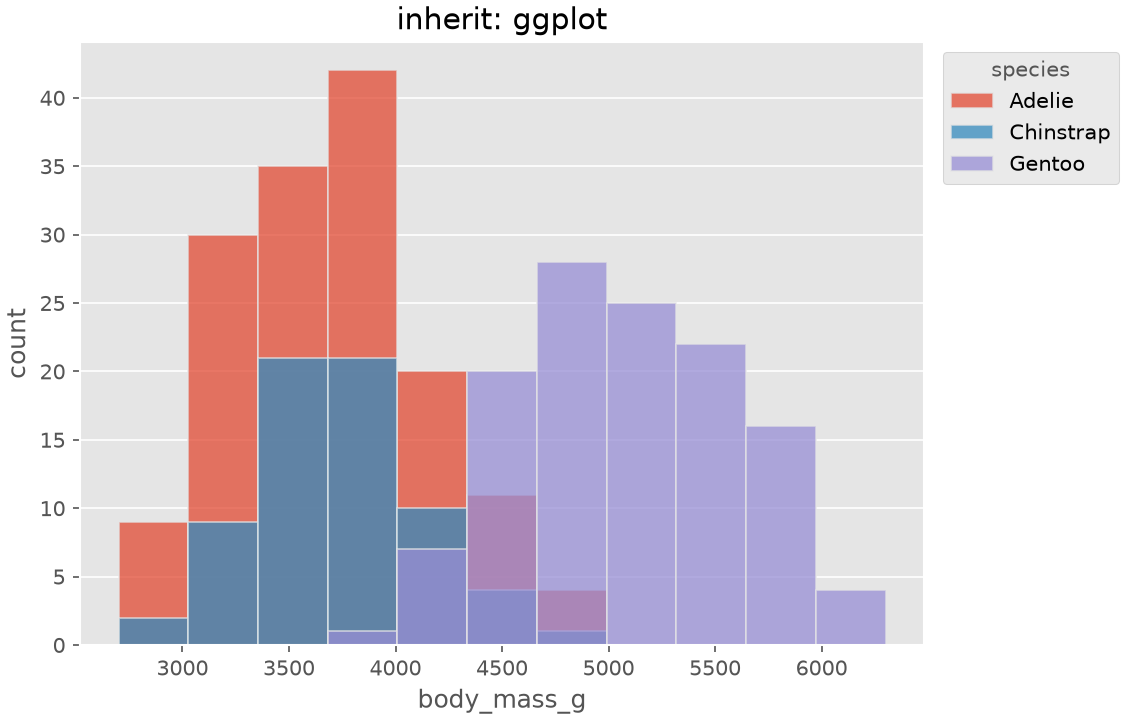

In [6]:
import matplotlib.pyplot as plt, seaborn as sns
with plt.style.context('ggplot'):
    c = pc.histogram(pen, 'body_mass_g', 'species', theme='inherit', title='inherit: ggplot')
c

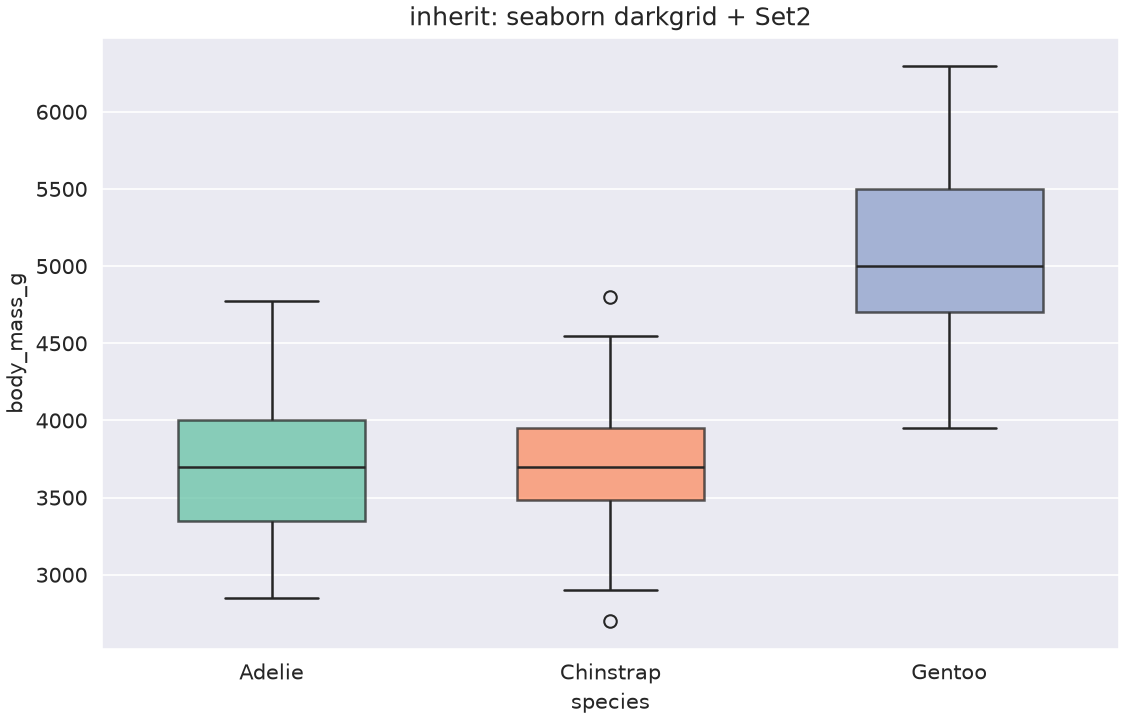

In [7]:
with sns.axes_style('darkgrid'), sns.color_palette('Set2'):
    c = pc.box(pen, 'species', 'body_mass_g', theme='inherit', backend='seaborn', title='inherit: seaborn darkgrid + Set2')
c

In [8]:
pio.templates.default = 'plotly_dark'
c = pc.bar(pen, 'species', 'body_mass_g', agg='mean', theme='inherit', backend='plotly', title='inherit: plotly_dark')
pio.templates.default = 'plotly'
c

<Chart kind='bar' backend='plotly' theme='plotly-plotly_dark'>

## Host presets
Match notebook/editor surfaces so the chart background blends in.

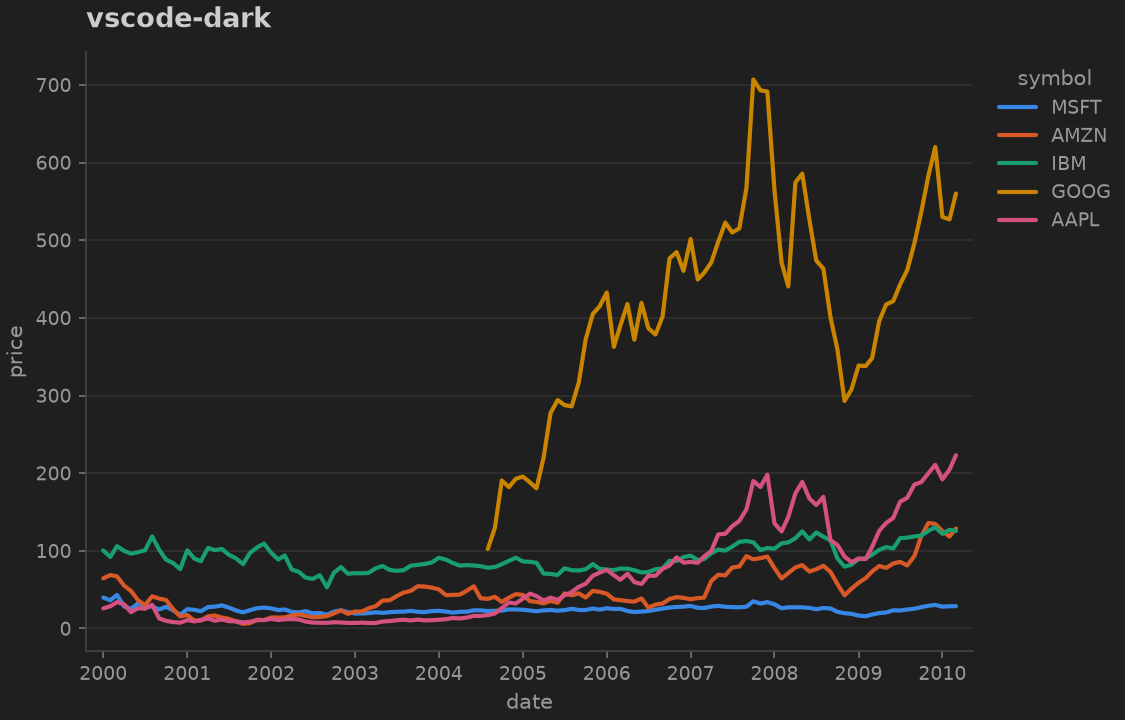

In [9]:
pc.line(pc.datasets.load('stocks'), 'date', 'price', 'symbol', theme='vscode-dark', title='vscode-dark')

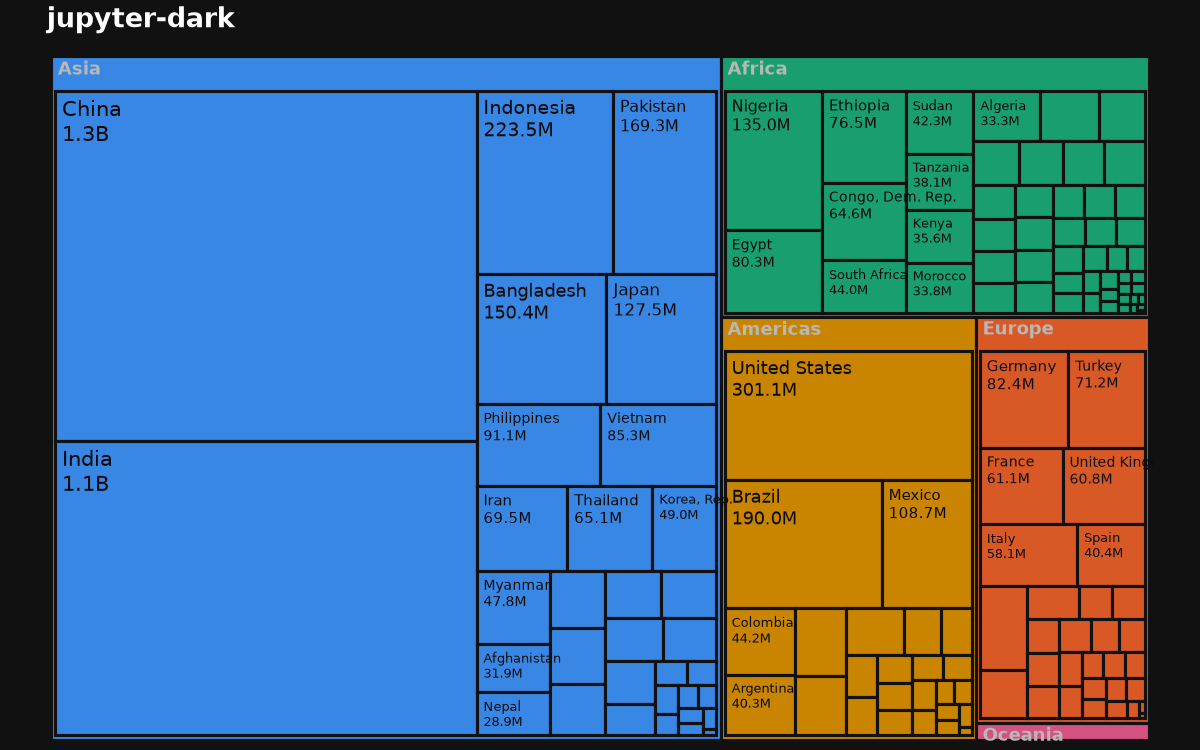

In [10]:
pc.treemap(pc.datasets.load('gapminder').query('year == 2007'), ['continent', 'country'], 'pop',
           theme='jupyter-dark', title='jupyter-dark')

## Bootstrap / Dash themes and transparency
In dashboards use a `-transparent` theme so the card shows through.

In [11]:
pc.donut(pen, 'species', theme='solar', backend='plotly', title='Bootswatch Solar')

<Chart kind='donut' backend='plotly' theme='solar'>

In [12]:
pc.from_bootstrap('DARKLY').with_transparent()

Theme(name='darkly-transparent', categorical=('#3987e5', '#d95926', '#199e70', '#c98500', '#d55181', '#008300', '#9085e9', '#e66767'), sequential=('#0d366b', '#184f95', '#256abf', '#3987e5', '#6da7ec', '#9ec5f4', '#cde2fb'), diverging=('#3987e5', '#3d3d3d', '#e66767'), surface='#222222', ink='#ffffff', ink_secondary='#bdbdbd', muted='#909090', grid='#383838', baseline='#535353', status={'good': '#0ca30c', 'warning': '#fab219', 'serious': '#ec835a', 'critical': '#d03b3b'}, font='DejaVu Sans', dark=True, transparent=True, inherit=False, plotly_base=None)

## Your own brand theme
`derive_theme` builds all chrome from a background (and optional text/palette); `register_theme` makes it available by name.

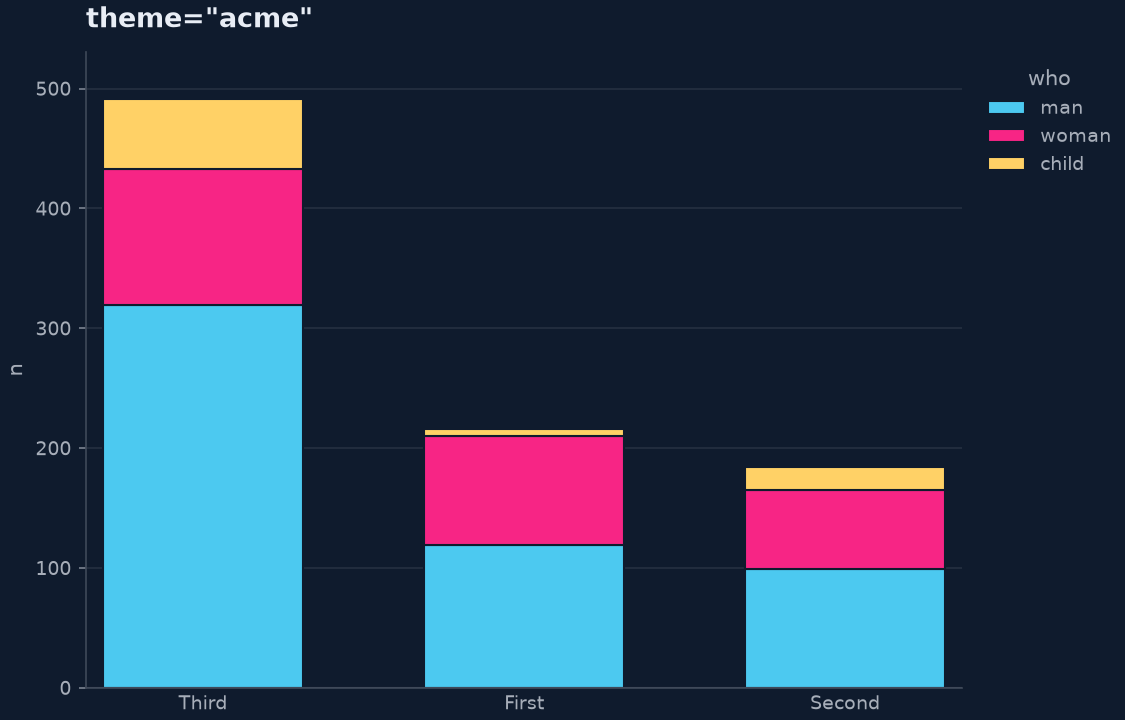

In [13]:
brand = pc.derive_theme('acme', surface='#0f1b2d', ink='#e8edf5',
                        categorical=['#4cc9f0', '#f72585', '#ffd166', '#06d6a0'], register=True)
pc.stacked_bar(pc.datasets.load('titanic').assign(n=1), 'class', 'n', 'who', theme='acme', title='theme="acme"')

In [14]:
pc.from_matplotlib('Solarize_Light2')

Theme(name='mpl-Solarize_Light2', categorical=('#268bd2', '#2aa198', '#859900', '#b58900', '#cb4b16', '#dc322f', '#d33682', '#6c71c4'), sequential=('#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b'), diverging=('#2a78d6', '#e0dac8', '#e34948'), surface='#eee8d5', ink='#000000', ink_secondary='#657b83', muted='#77746a', grid='#fdf6e3', baseline='#eee8d5', status={'good': '#0ca30c', 'warning': '#fab219', 'serious': '#ec835a', 'critical': '#d03b3b'}, font='DejaVu Sans', dark=False, transparent=False, inherit=False, plotly_base=None)

## Library looks: d3, nvd3 and chartist palettes

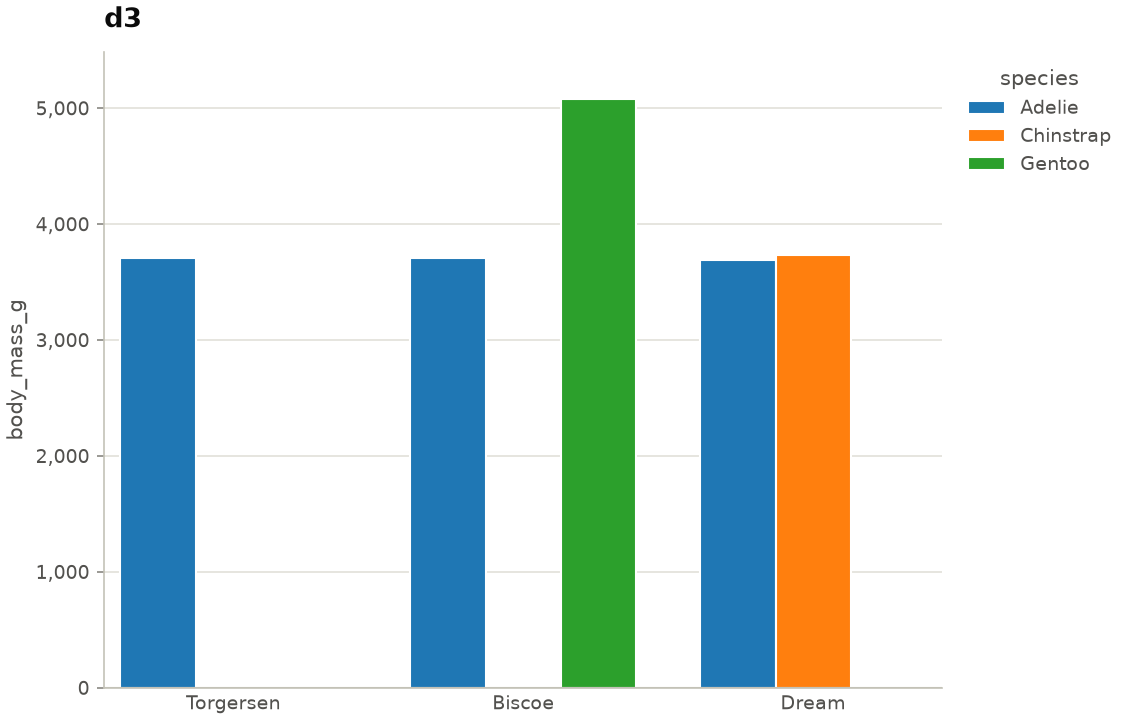

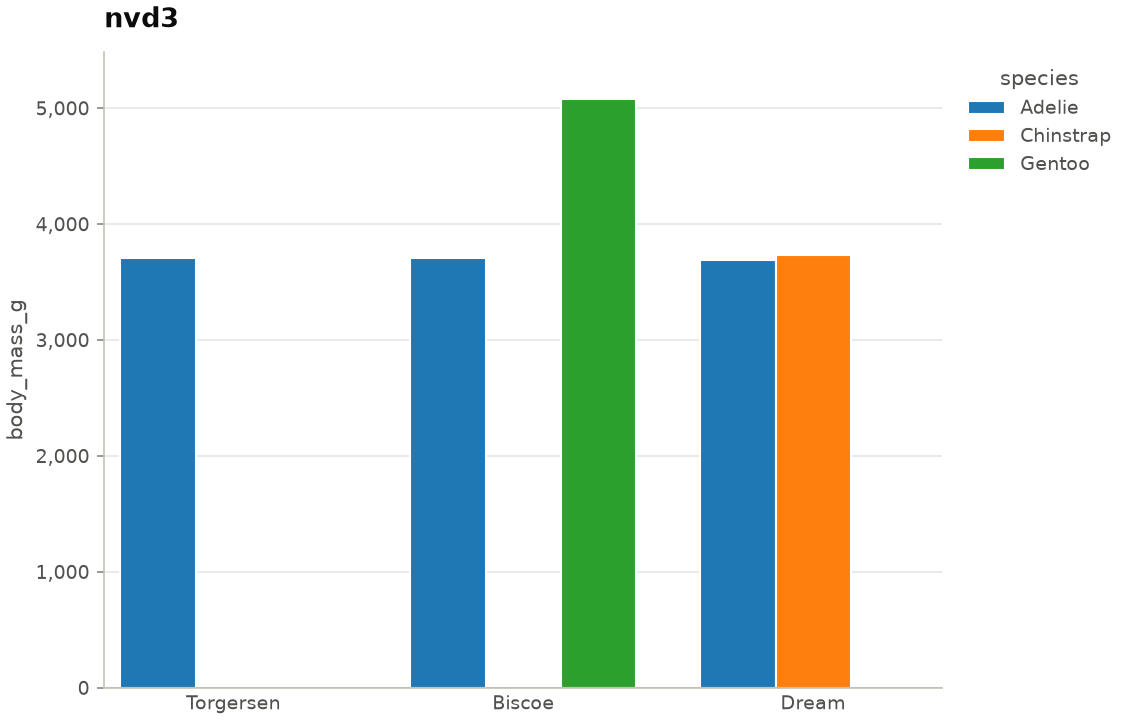

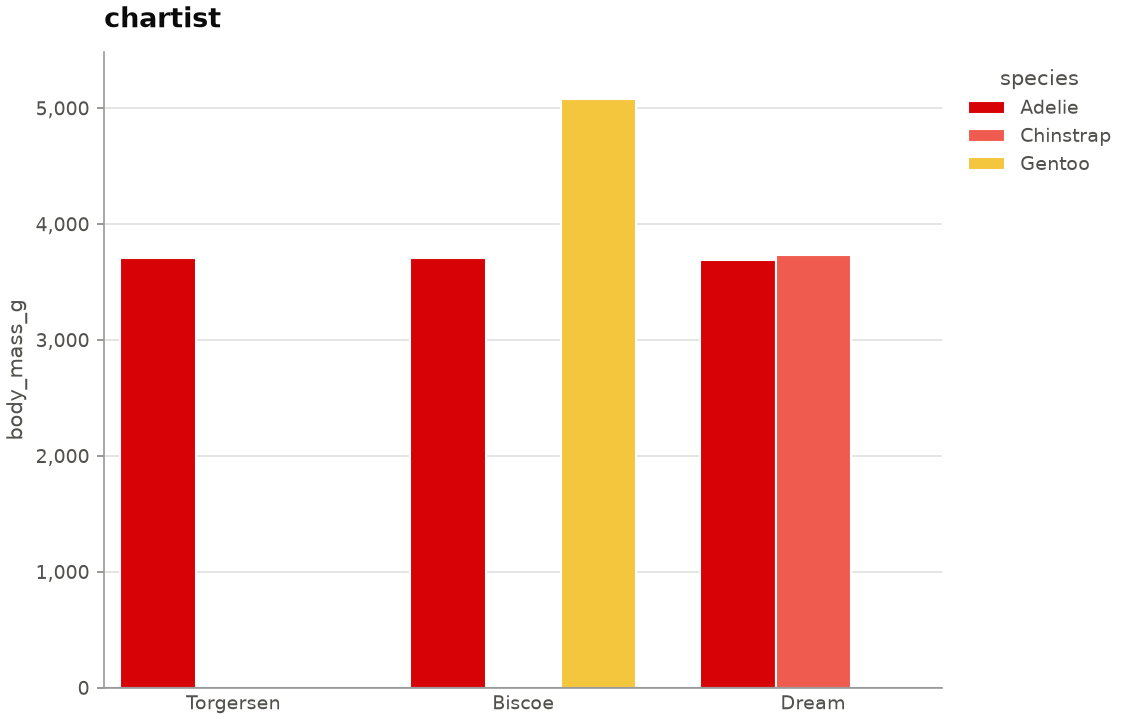

In [15]:
for t in ['d3', 'nvd3', 'chartist']:
    pc.grouped_bar(pen, 'island', 'body_mass_g', 'species', agg='mean', theme=t, title=t).show()

## Dashboards
`pychartist.dashboard.make_app` builds a Dash app whose charts re-render when the page switches light/dark. See `dashboards/` for complete apps; run one inline with `app.run(jupyter_mode='inline')`.

In [16]:
from pychartist.dashboard import make_app
app = make_app('Penguins', {'Mass': lambda th: pc.violin(pen, 'species', 'body_mass_g', backend='plotly', theme=th)})
app.pychartist['light'].name, app.pychartist['dark'].name

('bootstrap-transparent', 'darkly-transparent')